# Firefox Defect Analytics: Where Do Bugs Come From, and Where Should QA Focus?

**Business question:** Using three years of real Firefox defect reports (2023–2025), which parts of the
product generate the most bugs and regressions, how fast do different bugs get fixed, and where should
QA effort go?

**Data:** 13,422 defect reports filed against Firefox, pulled from Mozilla's public
[Bugzilla](https://bugzilla.mozilla.org) REST API with [`scripts/fetch_bugs.py`](../scripts/fetch_bugs.py).

**Approach:** the full analysis lifecycle: access → clean → explore → visualize → engineer features →
model → evaluate → recommend.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "firefox_bugs_2023_2025.csv"
CLEAN = ROOT / "data" / "clean" / "firefox_bugs_clean.csv"
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

# Chart styling: one consistent, colorblind-safe palette
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b9b8b2"
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": TEXT, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10.5, "figure.dpi": 110,
})

def save(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=150, bbox_inches="tight")

## Step 1: Access & filter

> **In plain words:** open the data and get your bearings. How big is it, what columns are there,
> and what does a row look like? Then practice pulling out just the rows you care about.

In [2]:
raw = pd.read_csv(RAW)
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head(3)

13,422 rows × 21 columns


,last_change_time,id,type,summary,creation_time,platform,cf_last_resolved,severity,component,priority,product,status,keywords,resolution,op_sys,is_confirmed,version,comment_count,votes,regressed_by_count,duplicates_count
0,2023-01-05T21:38:12Z,1808126,defect,windows builds failing with updater disabled w...,2023-01-01T15:32:15Z,Unspecified,2023-01-05T21:38:12Z,S3,Launcher Process,--,Firefox,RESOLVED,regression,FIXED,Unspecified,True,Trunk,9,0,1,0
1,2023-10-12T14:37:48Z,1808145,defect,"""Confirm before closing multiple tabs"" option ...",2023-01-01T19:20:18Z,Unspecified,2023-09-20T13:18:18Z,--,Tabbed Browser,--,Firefox,RESOLVED,NaN,INCOMPLETE,Unspecified,False,Firefox 108,8,0,0,0
2,2025-10-15T08:28:24Z,1808168,defect,RemoteSettingsWorker error: Error: Can't impor...,2023-01-02T08:57:00Z,Unspecified,NaN,S4,Remote Settings Client,--,Firefox,NEW,NaN,NaN,Unspecified,True,unspecified,5,0,0,0


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13422 entries, 0 to 13421
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   last_change_time    13422 non-null  object
 1   id                  13422 non-null  int64 
 2   type                13422 non-null  object
 3   summary             13422 non-null  object
 4   creation_time       13422 non-null  object
 5   platform            13422 non-null  object
 6   cf_last_resolved    11017 non-null  object
 7   severity            13378 non-null  object
 8   component           13422 non-null  object
 9   priority            13422 non-null  object
 10  product             13422 non-null  object
 11  status              13422 non-null  object
 12  keywords            5377 non-null   object
 13  resolution          10908 non-null  object
 14  op_sys              13422 non-null  object
 15  is_confirmed        13422 non-null  bool  
 16  version             13

Each row is **one bug report**. The columns that matter most:

| Column | Meaning |
|---|---|
| `component` | Which part of Firefox the bug is in (Address Bar, Tabbed Browser, PDF Viewer…) |
| `severity` | How bad it is: **S1** (critical) → **S4** (minor) |
| `priority` | How urgently the team plans to fix it: **P1** (now) → **P5** (someday) |
| `status` / `resolution` | Where the bug ended up: FIXED, DUPLICATE, INVALID, still open… |
| `creation_time` / `cf_last_resolved` | When it was reported / when it was closed |
| `keywords` | Tags. `regression` = something that used to work broke; `intermittent-failure` = a flaky automated test |

A few filtering examples (same skills as `loc` / Boolean filtering in class):

In [4]:
# Single condition: bugs in the Address Bar
address_bar = raw[raw["component"] == "Address Bar"]

# AND: serious (S2) Address Bar bugs
serious_address_bar = raw[(raw["component"] == "Address Bar") & (raw["severity"] == "S2")]

# isin(): bugs in any of the three busiest components
busiest = raw[raw["component"].isin(["Tabbed Browser", "Address Bar", "New Tab Page"])]

# between(): bugs with a lot of discussion (20 to 50 comments)
discussed = raw[raw["comment_count"].between(20, 50)]

print(f"Address Bar bugs: {len(address_bar):,}")
print(f"Serious (S2) Address Bar bugs: {len(serious_address_bar):,}")
print(f"Bugs in the 3 busiest components: {len(busiest):,}")
print(f"Bugs with 20–50 comments: {len(discussed):,}")

Address Bar bugs: 1,313
Serious (S2) Address Bar bugs: 117
Bugs in the 3 busiest components: 3,942
Bugs with 20–50 comments: 771


## Step 2: Data wrangling (cleaning)

> **In plain words:** real data is messy. Before trusting any numbers, find the problems and decide
> how to handle each one. Every decision here is written down so someone else could repeat it.

First, look at what's wrong:

In [5]:
print("Duplicate bug IDs:", raw["id"].duplicated().sum())
print()
print("Severity values:", raw["severity"].value_counts(dropna=False).to_dict())
print("Priority values:", raw["priority"].value_counts(dropna=False).to_dict())
print()
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])

Duplicate bug IDs: 0

Severity values: {'--': 5120, 'S3': 3990, 'S4': 3530, 'S2': 726, nan: 44, 'S1': 7, 'normal': 5}
Priority values: {'--': 6580, 'P3': 2120, 'P5': 2019, 'P1': 1607, 'P2': 1060, 'P4': 36}

Missing values per column:
cf_last_resolved    2405
severity              44
keywords            8045
resolution          2514
dtype: int64


**Problems found, and the fix for each:**

| Problem | Why it matters | Fix |
|---|---|---|
| Severity `--` or blank on ~5,100 bugs | It looks like a value but means "nobody rated this" | Label it `Not set` |
| 5 bugs use the old `normal` severity | Mozilla switched to S1–S4; `normal` maps to S3 | Recode `normal` → `S3` |
| Priority `--` | Same as severity | Label it `Not set` |
| Dates are stored as text | You can't do date math on text | Convert to real datetimes |
| Some **open** bugs still have a "resolved" date | They were closed, then **reopened**, so the old date is stale | Blank the resolved date for open bugs |
| `resolution` has 9 codes | Too detailed for a business audience | Group into 5 plain-English outcomes |
| `op_sys` has Windows / Windows 10 / Windows 11… | The same OS split three ways | Group into Windows / macOS / Linux / All / Unspecified |
| `keywords` is one text field | Hard to filter | Pull out `is_regression` and `is_flaky_test` yes/no flags |

In [6]:
df = raw.copy()

# Severity & priority: make "not rated" explicit, and recode the legacy value
df["severity"] = df["severity"].replace({"--": "Not set", "normal": "S3"}).fillna("Not set")
df["priority"] = df["priority"].replace({"--": "Not set"}).fillna("Not set")

# Text → real dates
for col in ["creation_time", "cf_last_resolved", "last_change_time"]:
    df[col] = pd.to_datetime(df[col], utc=True)

# Reopened bugs carry a stale resolved date: clear it if the bug is open now
is_open = df["resolution"].isna()
print("Open bugs with a stale resolved date:", (is_open & df["cf_last_resolved"].notna()).sum())
df.loc[is_open, "cf_last_resolved"] = pd.NaT

# Group the 9 resolution codes into outcomes a manager understands
outcome_map = {
    "FIXED": "Fixed",
    "DUPLICATE": "Duplicate",
    "INCOMPLETE": "Not actionable", "INVALID": "Not actionable",
    "WORKSFORME": "Not actionable", "INACTIVE": "Not actionable",
    "WONTFIX": "Won't fix", "MOVED": "Won't fix",
}
df["outcome"] = df["resolution"].map(outcome_map).fillna("Still open")

# Simplify operating system
def os_group(os_name):
    if pd.isna(os_name): return "Unspecified"
    if os_name.startswith("Windows"): return "Windows"
    if os_name in ("macOS", "Mac OS X"): return "macOS"
    if os_name == "Linux": return "Linux"
    if os_name == "All": return "All"
    return "Other" if os_name != "Unspecified" else "Unspecified"
df["os_group"] = df["op_sys"].apply(os_group)

# Keyword flags
kw = df["keywords"].fillna("").str.split(";")
df["is_regression"] = kw.apply(lambda k: "regression" in k).astype(int)
df["is_flaky_test"] = kw.apply(lambda k: "intermittent-failure" in k).astype(int)

# New time columns
df["days_to_resolve"] = (df["cf_last_resolved"] - df["creation_time"]).dt.total_seconds() / 86400
df["created_year"] = df["creation_time"].dt.year
df["created_quarter"] = df["creation_time"].dt.tz_localize(None).dt.to_period("Q").astype(str)

df[["id", "component", "severity", "outcome", "is_regression", "is_flaky_test", "days_to_resolve"]].head()

Open bugs with a stale resolved date: 112


,id,component,severity,outcome,is_regression,is_flaky_test,days_to_resolve
0,1808126,Launcher Process,S3,Fixed,1,0,4.254132
1,1808145,Tabbed Browser,Not set,Not actionable,0,0,261.748611
2,1808168,Remote Settings Client,S4,Still open,0,0,NaN
3,1808169,about:logins,Not set,Duplicate,0,0,1.132373
4,1808220,Firefox View,S4,Fixed,0,0,7.210498


**Outliers check.** Time-to-fix ranges from minutes to years. That's real (some bugs sit for ages),
so we **keep** those rows but use the **median** instead of the average. The median is the "typical"
bug and isn't dragged up by a handful of extreme ones.

In [7]:
print(df["days_to_resolve"].describe().round(1))
print()
print(f"Average days to resolve: {df['days_to_resolve'].mean():.1f}")
print(f"Median days to resolve:  {df['days_to_resolve'].median():.1f}   ← much lower: a few slow bugs inflate the average")

count    10905.0
mean        67.2
std        156.9
min          0.0
25%          1.6
50%          9.6
75%         39.0
max       1354.1
Name: days_to_resolve, dtype: float64

Average days to resolve: 67.2
Median days to resolve:  9.6   ← much lower: a few slow bugs inflate the average


In [8]:
# Save the clean version (this is also the file to load into Power BI)
CLEAN.parent.mkdir(parents=True, exist_ok=True)
export_cols = ["id", "summary", "component", "severity", "priority", "status", "resolution", "outcome",
               "creation_time", "cf_last_resolved", "days_to_resolve", "created_year", "created_quarter",
               "os_group", "is_regression", "is_flaky_test", "comment_count", "duplicates_count", "votes"]
df[export_cols].to_csv(CLEAN, index=False)
print(f"Saved {len(df):,} clean rows to {CLEAN.relative_to(ROOT)}")

Saved 13,422 clean rows to data\clean\firefox_bugs_clean.csv


## Steps 3 & 4: Explore and visualize

> **In plain words:** ask the data questions (group, count, compare) and turn each answer into a chart
> that makes the point obvious. Each question below has the code, a chart, and the takeaway.

### Q1. What actually happens to bug reports?

                bugs  % of reports
outcome                           
Fixed           4844          36.1
Not actionable  3413          25.4
Still open      2514          18.7
Duplicate       2144          16.0
Won't fix        507           3.8


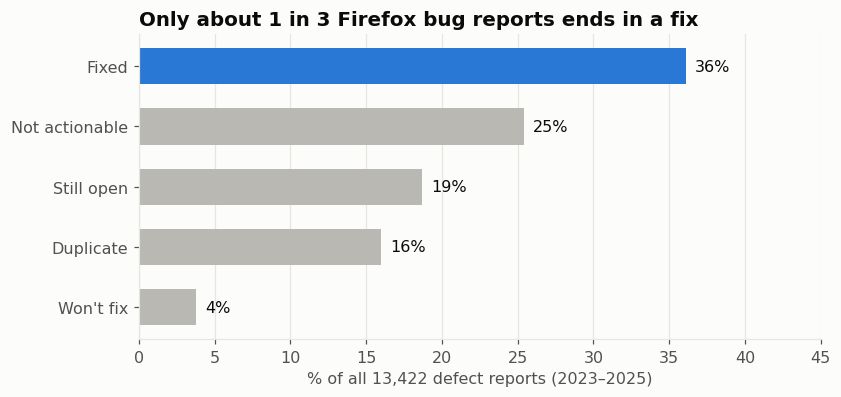

In [9]:
outcomes = df["outcome"].value_counts()
outcome_pct = (outcomes / len(df) * 100).round(1)
print(pd.DataFrame({"bugs": outcomes, "% of reports": outcome_pct}))

order = ["Fixed", "Not actionable", "Still open", "Duplicate", "Won't fix"]
vals = outcome_pct.reindex(order)
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [BLUE if o == "Fixed" else GRAY for o in order]
ax.barh(order[::-1], vals[::-1], color=colors[::-1], height=0.6)
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.6, i, f"{v:.0f}%", va="center", color=TEXT)
ax.set_title("Only about 1 in 3 Firefox bug reports ends in a fix")
ax.set_xlabel("% of all 13,422 defect reports (2023–2025)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 45)
save(fig, "01_outcomes")
plt.show()

**Takeaway:** only **~36%** of reports end in a code fix. About **41%** are duplicates or
"not actionable" (incomplete, invalid, can't reproduce). That's a lot of triage time spent on reports
that never become fixes. **Better bug report quality and duplicate detection would free up real QA capacity.**

### Q2. Which parts of Firefox produce the most real bugs and regressions?

In [10]:
by_comp = (df.groupby("component")
             .agg(reports=("id", "size"),
                  fixed=("outcome", lambda s: (s == "Fixed").sum()),
                  regressions=("is_regression", "sum"))
             .query("reports >= 200"))
by_comp["regression_rate_%"] = (by_comp["regressions"] / by_comp["reports"] * 100).round(1)
top = by_comp.sort_values("fixed", ascending=False).head(10)
top

,reports,fixed,regressions,regression_rate_%
component,,,,
Address Bar,1313,618,311,23.7
New Tab Page,1111,489,175,15.8
Tabbed Browser,1518,471,283,18.6
Messaging System,749,469,87,11.6
Sidebar,753,308,215,28.6
PDF Viewer,625,270,102,16.3
Translations,584,198,119,20.4
Theme,320,166,161,50.3
Settings UI,385,148,108,28.1


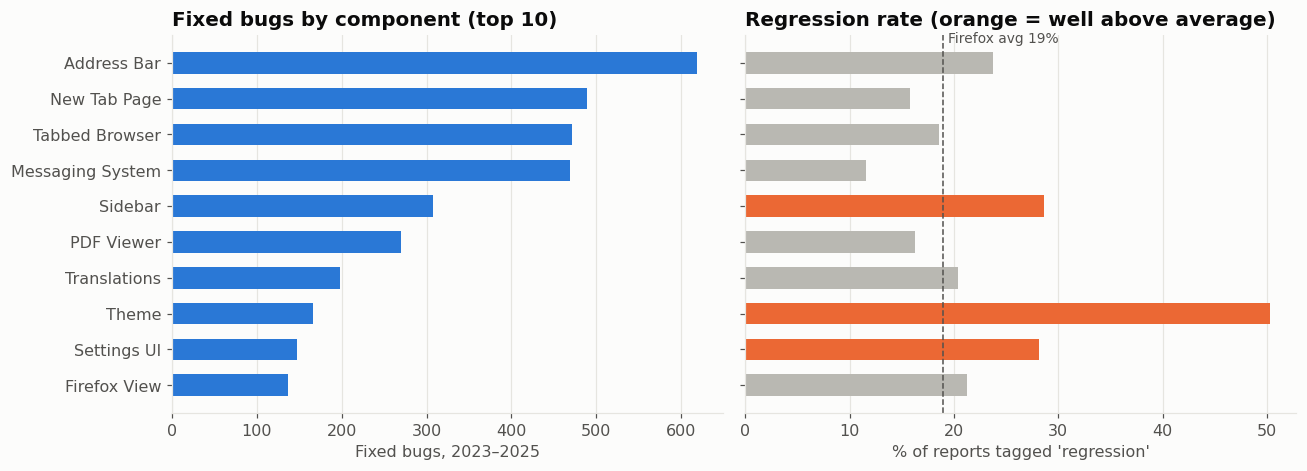

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
t = top.sort_values("fixed")

axes[0].barh(t.index, t["fixed"], color=BLUE, height=0.6)
axes[0].set_title("Fixed bugs by component (top 10)")
axes[0].set_xlabel("Fixed bugs, 2023–2025")
axes[0].grid(axis="y", visible=False)

avg_rate = df["is_regression"].mean() * 100
bar_colors = [ORANGE if r > avg_rate * 1.3 else GRAY for r in t["regression_rate_%"]]
axes[1].barh(t.index, t["regression_rate_%"], color=bar_colors, height=0.6)
axes[1].axvline(avg_rate, color=MUTED, linestyle="--", linewidth=1)
axes[1].text(avg_rate + 0.5, len(t) - 0.45, f"Firefox avg {avg_rate:.0f}%", color=MUTED, fontsize=9)
axes[1].set_title("Regression rate (orange = well above average)")
axes[1].set_xlabel("% of reports tagged 'regression'")
axes[1].grid(axis="y", visible=False)

fig.tight_layout()
save(fig, "02_components")
plt.show()

**Takeaway:** a handful of components (Address Bar, New Tab Page, Tabbed Browser, Messaging System)
produce the most fixed bugs. The **regression rate** tells a different story, though. **Theme** is the
standout: about **half** of its bug reports are regressions. **Sidebar** and **Settings UI** (~28%) are
also well above the ~19% Firefox average. Those are the places where **more regression test coverage**
would pay off most.

### Q3. How fast do bugs get fixed, by severity?

In [12]:
fixed = df[df["outcome"] == "Fixed"]
sev_order = ["S1", "S2", "S3", "S4", "Not set"]
by_sev = (fixed.groupby("severity")["days_to_resolve"]
               .agg(fixed_bugs="size", median_days="median", average_days="mean")
               .reindex(sev_order).round(1))
by_sev

,fixed_bugs,median_days,average_days
severity,,,
S1,7,3.3,9.2
S2,556,5.9,20.2
S3,2022,12.8,57.9
S4,1028,11.7,76.3
Not set,1231,3.0,15.6


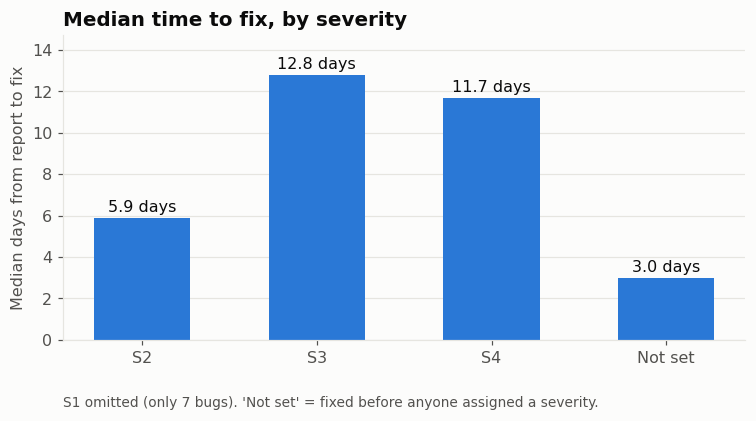

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.6))
plot = by_sev.drop(index="S1")   # only 7 S1 bugs: too few to chart fairly
ax.bar(plot.index, plot["median_days"], color=BLUE, width=0.55)
for i, v in enumerate(plot["median_days"]):
    ax.text(i, v + 0.3, f"{v:.1f} days", ha="center", color=TEXT)
ax.set_title("Median time to fix, by severity")
ax.set_ylabel("Median days from report to fix")
ax.set_ylim(0, plot["median_days"].max() * 1.15)
ax.grid(axis="x", visible=False)
ax.text(0, -0.22, "S1 omitted (only 7 bugs). 'Not set' = fixed before anyone assigned a severity.",
        transform=ax.transAxes, color=MUTED, fontsize=9)
save(fig, "03_fix_time_by_severity")
plt.show()

**Takeaway:** serious **S2** bugs get fixed about **twice as fast** as S3/S4 (≈6 days vs ≈12), so the
team does prioritise by severity. But **S3 and S4 take about the same time**, which suggests the S3/S4
distinction isn't really changing how work gets scheduled. Bugs with **no severity** are fixed fastest
of all (≈3 days): many are quick fixes the developer handled before triage ever happened.

### Q4. Are regressions treated differently?

In [14]:
reg = (df.assign(kind=np.where(df["is_regression"] == 1, "Regression", "Other bug"))
         .groupby("kind")
         .agg(reports=("id", "size"),
              fix_rate=("outcome", lambda s: (s == "Fixed").mean() * 100)))
reg["median_days_to_fix"] = fixed.groupby(np.where(fixed["is_regression"] == 1, "Regression", "Other bug"))["days_to_resolve"].median()
reg.round(1)

,reports,fix_rate,median_days_to_fix
kind,,,
Other bug,10885,28.8,10.2
Regression,2537,67.2,4.6


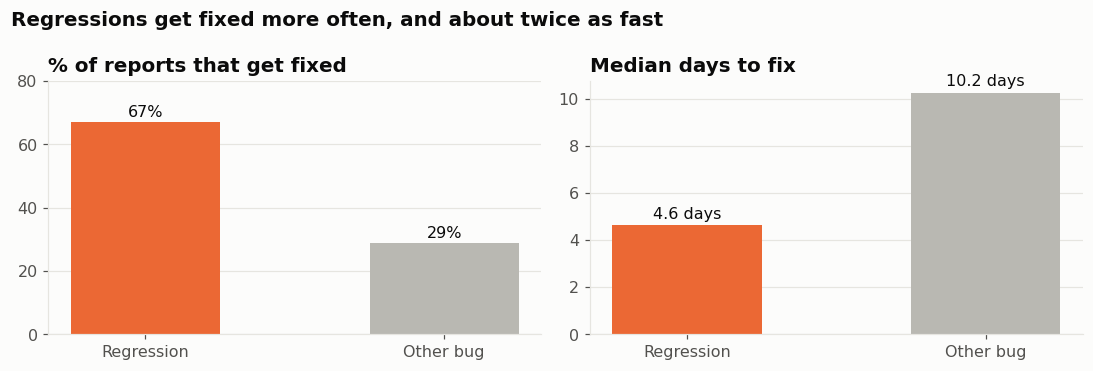

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
kinds = ["Regression", "Other bug"]
cols = [ORANGE, GRAY]

axes[0].bar(kinds, reg.loc[kinds, "fix_rate"], color=cols, width=0.5)
for i, v in enumerate(reg.loc[kinds, "fix_rate"]):
    axes[0].text(i, v + 1.5, f"{v:.0f}%", ha="center")
axes[0].set_title("% of reports that get fixed")
axes[0].set_ylim(0, 80)

axes[1].bar(kinds, reg.loc[kinds, "median_days_to_fix"], color=cols, width=0.5)
for i, v in enumerate(reg.loc[kinds, "median_days_to_fix"]):
    axes[1].text(i, v + 0.3, f"{v:.1f} days", ha="center")
axes[1].set_title("Median days to fix")

for ax in axes:
    ax.grid(axis="x", visible=False)
fig.suptitle("Regressions get fixed more often, and about twice as fast", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "04_regressions")
plt.show()

**Takeaway:** regressions are **more than twice as likely to get fixed** and get fixed in about
**half the time**. Once something is labelled a regression (and usually linked to the change that
caused it), it's easy to act on. That shows the value of **catching regressions early and tying them
to the change that caused them**, which is exactly what a strong regression suite does.

*(Caveat: the `regression` tag is often added after someone confirms the problem, so tagged bugs are
already "validated". Part of this gap is that effect, not only faster handling.)*

### Q5. Is bug volume growing?

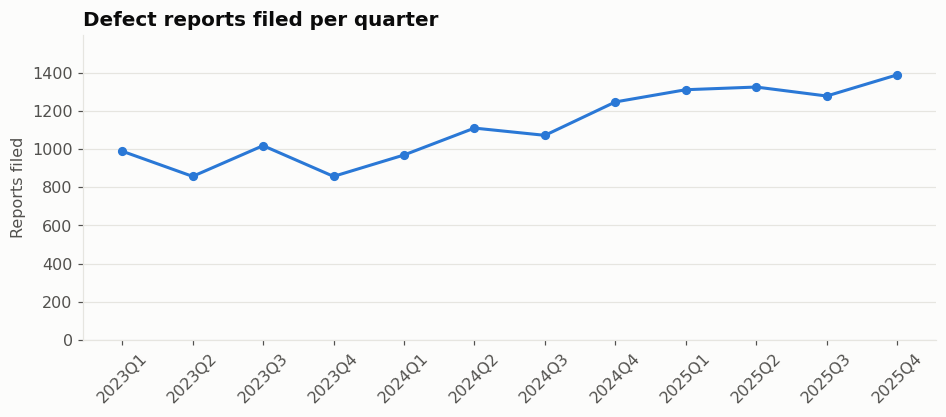

{2023: 3721, 2024: 4398, 2025: 5303}
Growth 2023 → 2025: 43%


In [16]:
quarterly = df.groupby("created_quarter").size()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(quarterly.index, quarterly.values, color=BLUE, linewidth=2, marker="o", markersize=5)
ax.set_title("Defect reports filed per quarter")
ax.set_ylabel("Reports filed")
ax.set_ylim(0, quarterly.max() * 1.15)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
save(fig, "05_volume_trend")
plt.show()

yearly = df.groupby("created_year").size()
print(yearly.to_dict())
print(f"Growth 2023 → 2025: {(yearly[2025] / yearly[2023] - 1) * 100:.0f}%")

**Takeaway:** reports filed per year grew by about **43%** from 2023 (3,721) to 2025 (5,303). Incoming work is
rising, so the triage and duplicate problem from Q1 gets more expensive every year.

### Q6. How much of this is flaky automated tests?

In [17]:
flaky = df[df["is_flaky_test"] == 1]
print(f"Flaky-test reports: {len(flaky):,} ({len(flaky) / len(df) * 100:.0f}% of all reports)")
print()
print("What happened to them:")
print((flaky["outcome"].value_counts(normalize=True) * 100).round(1).to_string())
print()
print("Top components for flaky tests:")
print(flaky["component"].value_counts().head(5).to_string())

Flaky-test reports: 2,011 (15% of all reports)

What happened to them:
outcome
Not actionable    64.3
Fixed             20.4
Still open         9.1
Duplicate          5.7
Won't fix          0.5

Top components for flaky tests:
component
Tabbed Browser         258
Address Bar            240
Translations           193
Search                 110
Bookmarks & History    101


**Takeaway:** about **15% of all defect reports** are automatically filed for **intermittent (flaky)
test failures** in Mozilla's CI pipeline. Most of them never lead to a code fix: they close as
"not actionable" once the failure stops recurring. Flaky tests cost triage time *and* erode trust in
the test suite. **Stabilising or quarantining the flakiest tests** would cut a large share of the noise.

### Q7. What's sitting in the open backlog?

In [18]:
open_bugs = df[df["outcome"] == "Still open"].copy()
as_of = df["last_change_time"].max()
open_bugs["age_days"] = (as_of - open_bugs["creation_time"]).dt.days
print(f"Open bugs: {len(open_bugs):,}")
print(f"Median age: {open_bugs['age_days'].median():.0f} days")
print(f"Open with no severity: {(open_bugs['severity'] == 'Not set').sum():,}")
print(f"Open with no priority: {(open_bugs['priority'] == 'Not set').sum():,}")
open_bugs.groupby("created_year").size().rename("open bugs").to_frame()

Open bugs: 2,514
Median age: 690 days
Open with no severity: 335
Open with no priority: 832


,open bugs
created_year,
2023,598
2024,732
2025,1184


**Takeaway:** about **2,500 bugs** from this period are still open, and the typical one is close to
**two years old**. 335 have never been given a severity and 832 have no priority, so nobody has
decided whether they matter.
A periodic **backlog sweep** (close what's stale, rate what's left) would make the real risk visible.

### Bonus: the same questions in SQL

> **In plain words:** analysts often answer these questions with SQL instead of Python. Here the clean
> data is loaded into a small SQLite database and every query in [`sql/queries.sql`](../sql/queries.sql) is run.

In [19]:
con = sqlite3.connect(":memory:")
df[export_cols].assign(creation_time=df["creation_time"].astype(str),
                       cf_last_resolved=df["cf_last_resolved"].astype(str)).to_sql("bugs", con, index=False)

sql_text = (ROOT / "sql" / "queries.sql").read_text()
queries = {}
for block in sql_text.split("-- name: ")[1:]:
    name, body = block.split("\n", 1)
    queries[name.strip()] = body

for name, q in queries.items():
    print(f"── {name} ──")
    print(pd.read_sql(q, con).to_string(index=False))
    print()

── outcome_breakdown ──


       outcome  bugs  pct_of_reports
         Fixed  4844            36.1
Not actionable  3413            25.4
    Still open  2514            18.7
     Duplicate  2144            16.0
     Won't fix   507             3.8

── components_fixed_and_regressions ──
       component  reports  fixed_bugs  regressions  regression_rate_pct
     Address Bar     1313         618          311                 23.7
    New Tab Page     1111         489          175                 15.8
  Tabbed Browser     1518         471          283                 18.6
Messaging System      749         469           87                 11.6
         Sidebar      753         308          215                 28.6
      PDF Viewer      625         270          102                 16.3
    Translations      584         198          119                 20.4
           Theme      320         166          161                 50.3
     Settings UI      385         148          108                 28.1
    Firefox View 

## Step 5: Feature engineering

> **In plain words:** to predict something, the model needs useful inputs ("features"). We create
> columns from information that exists **at the moment a bug is filed**, because a triage tool
> can't use information from the future.

**Prediction goal:** when a new bug report arrives, can we predict whether it will **end up fixed**?
That would help triagers spot the reports worth looking at first.

**Important:** we only use things known on day one (component, OS, the title text, whether a bot filed it).
We do **not** use severity, priority, or comment count, because those are added *later* and would be
"cheating" (this is called **data leakage**).

In [20]:
closed = df[df["outcome"] != "Still open"].copy()      # only bugs whose fate we know
closed["was_fixed"] = (closed["outcome"] == "Fixed").astype(int)

# Features from the title (summary) text
title = closed["summary"].fillna("").str.lower()
closed["title_words"] = title.str.split().str.len()
closed["title_has_crash"] = title.str.contains("crash").astype(int)
closed["title_has_error_text"] = title.str.contains(r"error|exception|assert|fail").astype(int)
closed["title_mentions_test"] = title.str.contains(r"test|\.js|\.html|browser_").astype(int)

# Keep the 15 most common components, and lump the rest into "Other" so the model isn't too spread out
top_components = closed["component"].value_counts().head(15).index
closed["component_grp"] = closed["component"].where(closed["component"].isin(top_components), "Other")

# One-hot encoding: turn text categories into 0/1 columns the model can read
X = pd.get_dummies(closed[["component_grp", "os_group"]], drop_first=False, dtype=int)
X = X.join(closed[["title_words", "title_has_crash", "title_has_error_text", "title_mentions_test", "is_flaky_test"]])
y = closed["was_fixed"]

print(f"{X.shape[0]:,} closed bugs, {X.shape[1]} features")
print(f"Share actually fixed: {y.mean() * 100:.1f}%")
X.head()

10,908 closed bugs, 27 features

Share actually fixed: 44.4%


,component_grp_Address Bar,component_grp_Bookmarks & History,component_grp_Firefox View,component_grp_General,component_grp_Messaging System,component_grp_New Tab Page,component_grp_Other,component_grp_PDF Viewer,component_grp_Search,component_grp_Session Restore,component_grp_Settings UI,component_grp_Sidebar,component_grp_Tabbed Browser,component_grp_Theme,component_grp_Translations,component_grp_Untriaged,os_group_All,os_group_Linux,os_group_Other,os_group_Unspecified,os_group_Windows,os_group_macOS,title_words,title_has_crash,title_has_error_text,title_mentions_test,is_flaky_test
0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,11,0,1,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,13,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,22,0,0,0,0
4,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,10,0,0,0,0
5,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,4,1,0,0,0


## Step 6: Modeling

> **In plain words:** split the data. The model learns from 80% (the *training set*) and is tested on
> the 20% it has never seen (the *test set*), the same way you'd check a student on new exam questions,
> not the ones they practised.

We try two models:
- **Logistic regression**: simple and explainable, a good baseline
- **Random forest**: many decision trees voting together, which can catch more complex patterns

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}
for name, m in models.items():
    m.fit(X_train, y_train)
print("Trained:", ", ".join(models))

Trained: Logistic regression, Random forest


## Step 7: Evaluation

> **In plain words:**
> - **Accuracy**: % of predictions that were right overall
> - **Precision**: of the bugs the model *said* would be fixed, how many really were? (are its "yes" calls trustworthy?)
> - **Recall**: of the bugs that *really* got fixed, how many did the model catch? (does it miss many?)
> - **F1**: one score balancing precision and recall
>
> We compare against a **dumb baseline** that always guesses "not fixed". A model is only useful if it
> beats that.

In [22]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

rows = [{"model": "Baseline (always 'not fixed')", "accuracy": 1 - y_test.mean(),
         "precision": 0.0, "recall": 0.0, "f1": 0.0}]
for name, m in models.items():
    p = m.predict(X_test)
    rows.append({"model": name, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p), "f1": f1_score(y_test, p)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,precision,recall,f1
model,,,,
Baseline (always 'not fixed'),0.556,0.000,0.000,0.000
Logistic regression,0.659,0.589,0.770,0.668
Random forest,0.669,0.596,0.792,0.680


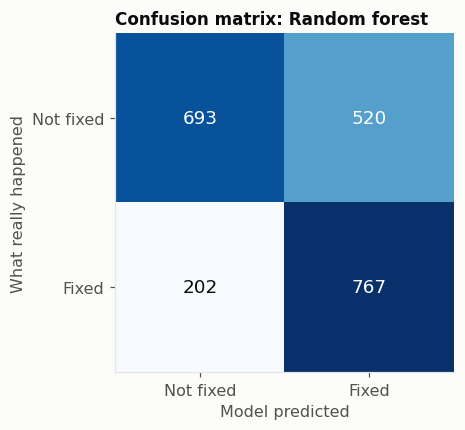

In [23]:
best_name = results.drop(index=results.index[0])["f1"].idxmax()
best = models[best_name]
cm = confusion_matrix(y_test, best.predict(X_test))

fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
labels = ["Not fixed", "Fixed"]
ax.set_xticks([0, 1], labels); ax.set_yticks([0, 1], labels)
ax.set_xlabel("Model predicted"); ax.set_ylabel("What really happened")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else TEXT, fontsize=12)
ax.grid(False)
ax.set_title(f"Confusion matrix: {best_name}", fontsize=11)
save(fig, "06_confusion_matrix")
plt.show()

In [24]:
# What drives the prediction? (Random forest feature importance)
rf = models["Random forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importance.round(3)

title_words                          0.295
component_grp_Untriaged              0.196
is_flaky_test                        0.086
os_group_All                         0.057
component_grp_Messaging System       0.050
title_mentions_test                  0.038
os_group_Unspecified                 0.037
component_grp_New Tab Page           0.037
component_grp_Bookmarks & History    0.030
component_grp_General                0.023
dtype: float64

**Takeaway:** the random forest gets **67% accuracy vs 56% for the baseline**, and catches **~79% of
the bugs that really got fixed** (recall), though only ~60% of its "will be fixed" calls are right
(precision). It isn't accurate enough to make decisions on its own, but it's useful as a **triage helper**
that sorts incoming reports so the likely-real ones get looked at first.

The strongest signals are **title length** (detailed titles → more likely real), the **Untriaged**
component, and whether it's a **flaky-test** report.

⚠️ **Honest caveat about "Untriaged":** Bugzilla stores a bug's *current* component, not the one it was
filed under. Triagers move bugs *out* of Untriaged when they look at them, so a bug still in Untriaged
mostly means "nobody ever triaged it", and that's partly future information leaking in. A production
version would need the component *as originally filed* (available from each bug's change history).

## Step 8: Recommendations

> **In plain words:** finding → evidence → what to do about it.

| # | Finding | Evidence | Recommendation |
|---|---|---|---|
| 1 | Most bug reports never become fixes | ~36% fixed; ~41% duplicates or not actionable (Q1) | Improve report templates (steps to reproduce, version, OS) and add duplicate search at filing time |
| 2 | Regression risk is concentrated | Theme (~50%), Sidebar and Settings UI (~28%) vs ~19% Firefox average (Q2) | Prioritise regression test coverage for the highest-rate components before releases |
| 3 | Regressions are fixed fast once identified | 2× fix rate and ~½ the time of other bugs (Q4) | Invest in catching regressions early (pre-merge regression suites, linking to the change that caused them) |
| 4 | S3 vs S4 makes little difference in practice | Similar median fix times (Q3) | Review whether the severity scale is guiding scheduling, or simplify it |
| 5 | Flaky tests create a lot of noise | ~15% of reports are intermittent test failures, mostly never fixed (Q6) | Track and quarantine the flakiest tests; prioritise stabilising them |
| 6 | The backlog is old and partly unrated | ~2,500 open, median ~2 years old (Q7) | Run a quarterly backlog sweep: close stale bugs, rate the rest |
| 7 | Fix-likelihood is partly predictable | Model beats baseline using only day-one info (Step 7) | Pilot a triage-ranking helper; don't automate closures |

### Limitations
- **One product, one company.** These are Firefox's processes; other teams triage differently.
- **Tags are added by people.** `regression` and severity depend on who triaged the bug and when.
- **"Resolved date" = last resolution.** A bug fixed, reopened, then fixed again shows the final date.
- **Component is the current value.** Bugs get moved between components during triage (see Step 7 caveat).
- **Correlation, not causation.** For example, the regression gap is partly caused by *how* the tag gets applied (see Q4).